In [1]:
# import modules
import numpy as np
import tensorflow as tf
from tensorflow import keras
import pandas as pd
import seaborn as sns
from pylab import rcParams
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from scipy import stats
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras import optimizers
from datetime import datetime
from kerastuner.tuners import RandomSearch


r_seed = 42

WORKDIR = 'C:/Users/thewr/git/LSTM_giroscopio_acelerometro.git/'
np.random.seed(r_seed)
tf.random.set_seed(r_seed)
data_hora= datetime.now().strftime('%Y-%m-%d_%H-%M-%S')
LOG_DIR = WORKDIR + "/Code/DataPrep/"+data_hora

C:\Users\thewr\AppData\Local\Temp\ipykernel_20240\604600442.py:15: DeprecationWarning: `import kerastuner` is deprecated, please use `import keras_tuner`.
  from kerastuner.tuners import RandomSearch


In [2]:
date = datetime.now()
date = date.strftime("%d/%m/%Y_%H:%M")
arq = datetime.now()
arq = arq.strftime("%d_%m_%Y_%H_%M")

In [3]:
## get dataset

# select only sensor data from smart watches
data = pd.read_csv('normalizado.csv')

In [4]:
data.shape


(3368542, 9)

In [5]:
data.head()

,pessoa_x,atividade,tempo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z
0,1600,0,90426757696641,4.972757,-0.158317,6.696732,0.314944,-1.022277,-0.309962
1,1600,0,90426807196641,3.253720,-0.191835,6.107758,0.387382,-0.618541,-0.048972
2,1600,0,90426856696641,2.801216,-0.155922,5.997625,0.070999,-0.209480,-0.195978
3,1600,0,90426906196641,3.770868,-1.051354,7.731027,0.037975,0.254976,-0.156563
4,1600,0,90426955696641,4.661511,0.169689,9.684695,0.073129,0.719431,-0.001035


In [6]:
data.isnull().sum()

pessoa_x          0
atividade         0
tempo             0
acelerômetro_x    0
acelerômetro_Y    0
acelerômetro_Z    0
giroscópio_x      0
giroscópio_Y      0
giroscópio_Z      0
dtype: int64

In [7]:
#remove the null class
data=data.dropna()

# **Data Exploration**

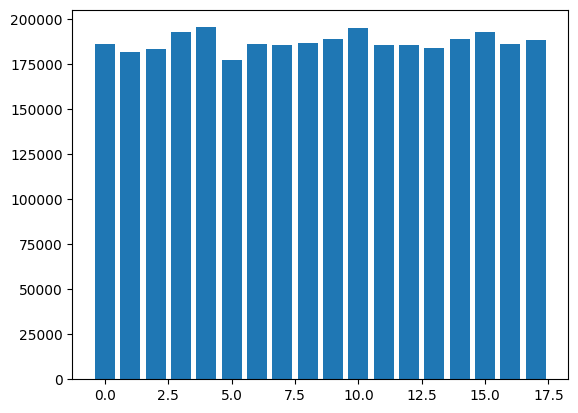

In [8]:
## the distribution of output classes
plt.bar(data["atividade"].value_counts().index, data["atividade"].value_counts().values)
plt.show()

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

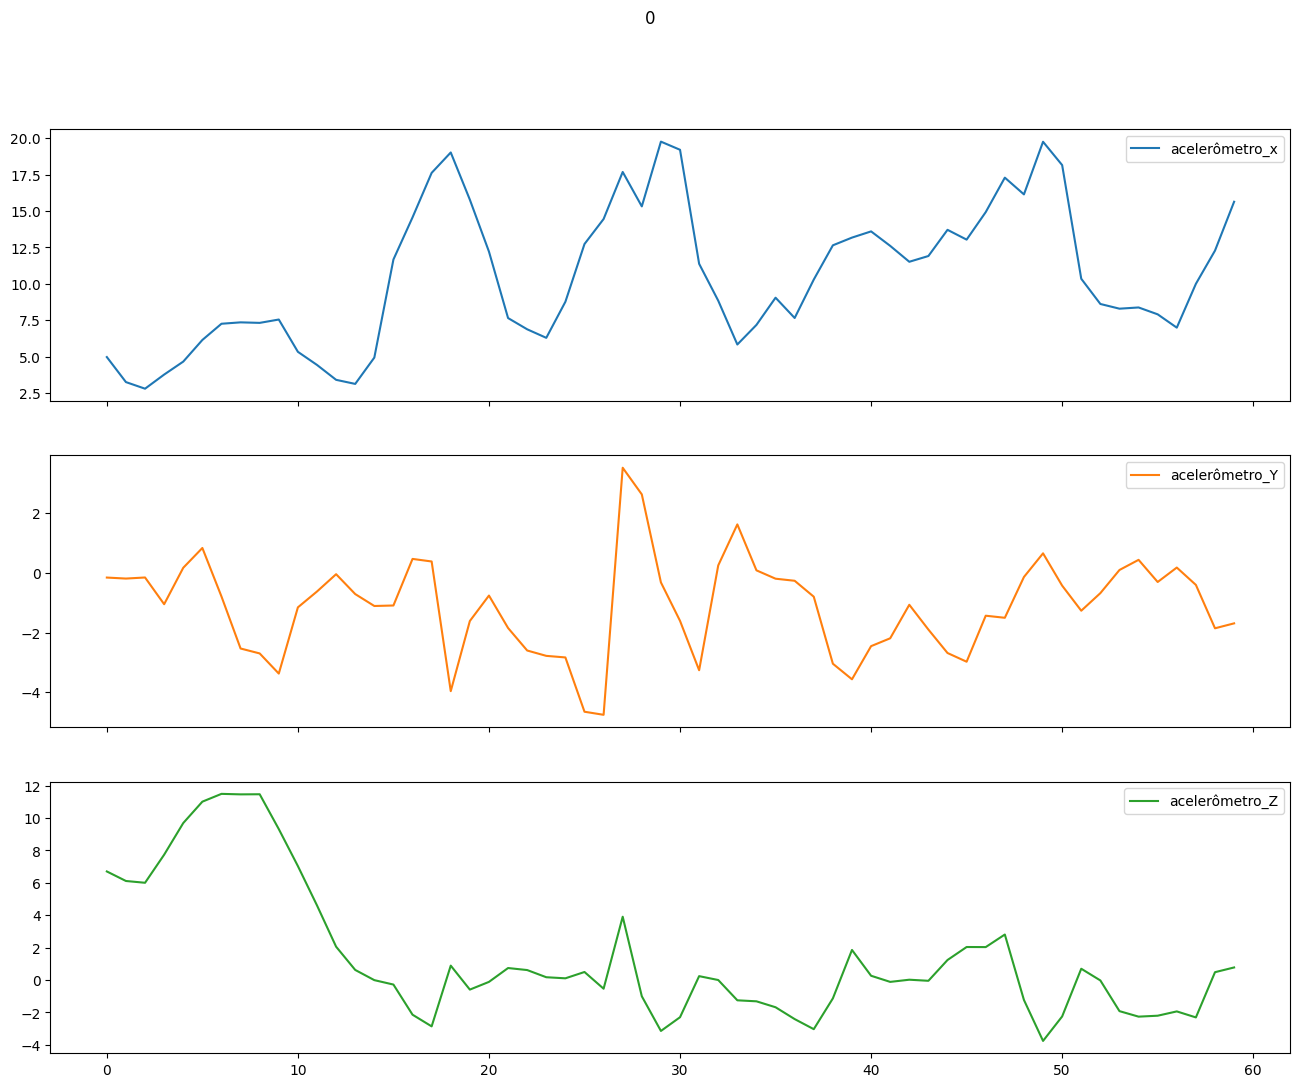

In [9]:
## x,y,z vaues for activity 'sit' 
data[(data['atividade'] == 0 )&(data['pessoa_x']==1600)][['acelerômetro_x','acelerômetro_Y','acelerômetro_Z']][:60].plot(title='0',subplots=True, figsize=(16, 12))

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

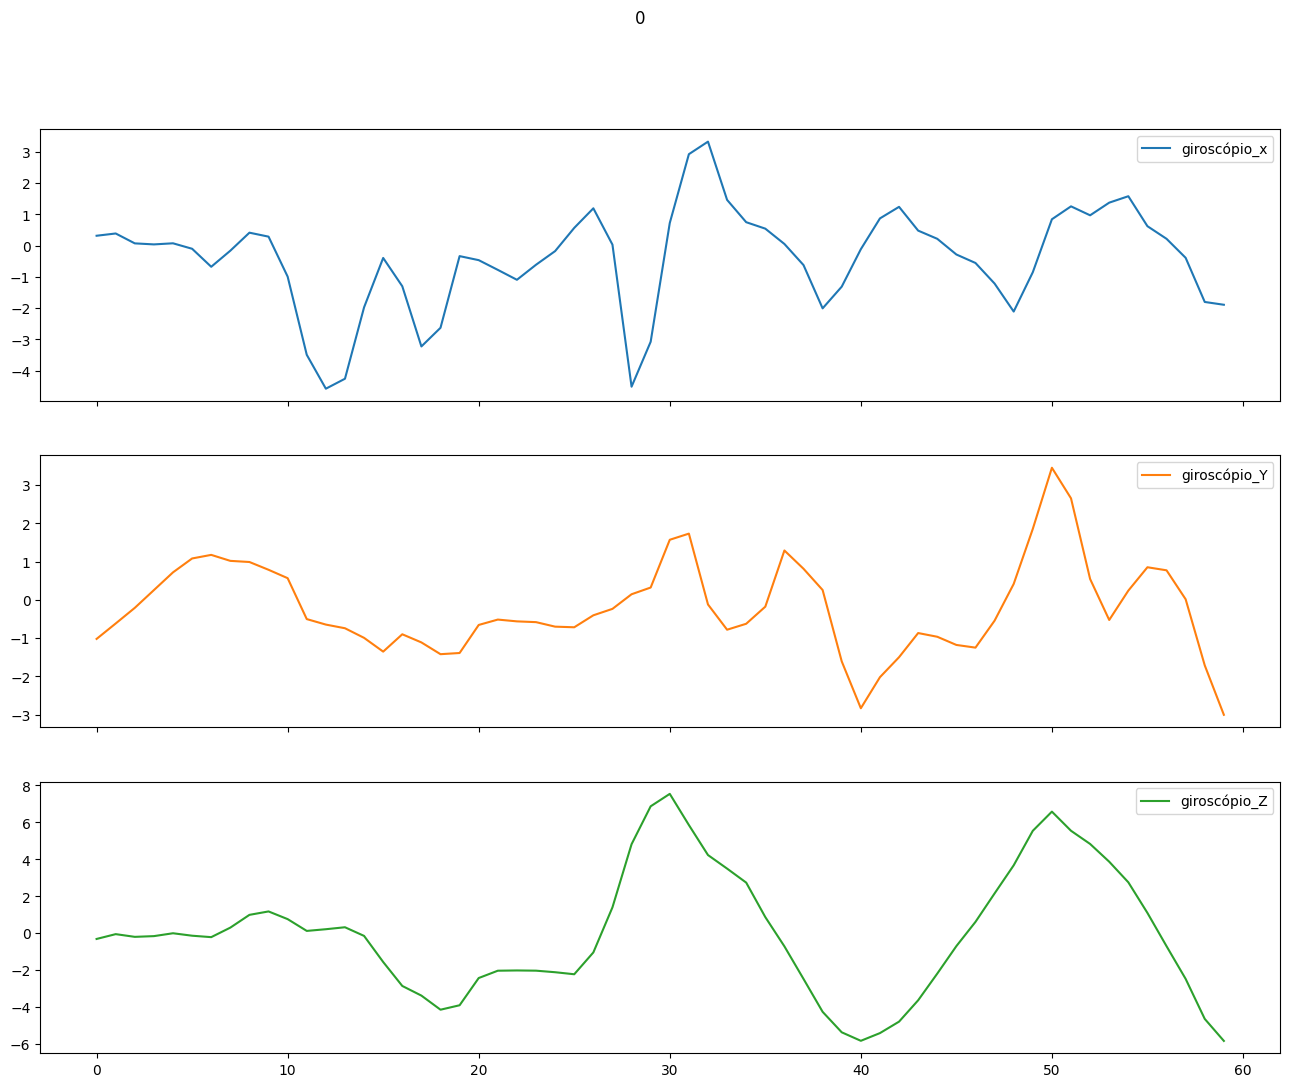

In [10]:
## x,y,z vaues for activity 'stand' 
data[(data['atividade'] == 0 )&(data['pessoa_x']==1600)][['giroscópio_x','giroscópio_Y','giroscópio_Z']][:60].plot(title='0',subplots=True, figsize=(16, 12))

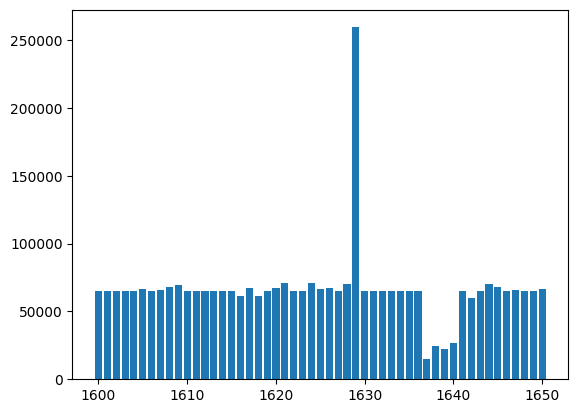

In [11]:
## number of events per user

plt.bar(data["pessoa_x"].value_counts().index, data["pessoa_x"].value_counts().values)
plt.show()

In [12]:
data = data[data["atividade"].isin([0,1,2,3])]

In [13]:
data.shape

(743625, 9)

In [14]:
data.head()

,pessoa_x,atividade,tempo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z
0,1600,0,90426757696641,4.972757,-0.158317,6.696732,0.314944,-1.022277,-0.309962
1,1600,0,90426807196641,3.253720,-0.191835,6.107758,0.387382,-0.618541,-0.048972
2,1600,0,90426856696641,2.801216,-0.155922,5.997625,0.070999,-0.209480,-0.195978
3,1600,0,90426906196641,3.770868,-1.051354,7.731027,0.037975,0.254976,-0.156563
4,1600,0,90426955696641,4.661511,0.169689,9.684695,0.073129,0.719431,-0.001035


# **Models**

In [15]:
X = data[['acelerômetro_x','acelerômetro_Y','acelerômetro_Z','giroscópio_x','giroscópio_Y','giroscópio_Z']]
y = data[['atividade']]





In [16]:
X.head()

,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z
0,4.972757,-0.158317,6.696732,0.314944,-1.022277,-0.309962
1,3.253720,-0.191835,6.107758,0.387382,-0.618541,-0.048972
2,2.801216,-0.155922,5.997625,0.070999,-0.209480,-0.195978
3,3.770868,-1.051354,7.731027,0.037975,0.254976,-0.156563
4,4.661511,0.169689,9.684695,0.073129,0.719431,-0.001035


In [17]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=r_seed, shuffle=False)

In [18]:
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)


(594900, 6)
(594900, 1)
(148725, 6)
(148725, 1)


In [19]:
def cria_IN_OUT(data, janela, features):
    OUT_indices = np.arange(janela, len(data), janela)
    #print("imprimindo out_indices")
    #print(OUT_indices)
    OUT = data[OUT_indices]
    #print("imprimindo out")
    #print(OUT)
    IN_indices = [range(i-janela, i) for i in OUT_indices] 
    #print("imprimindo IN_INDICES")
    #print(IN_indices)  
    #print("imprimindo IN_indices flattened") 
    #print(np.array(IN_indices).flatten())
    IN = data[np.array(IN_indices).flatten()]
    #print("imprimindo IN")
    #print(IN)      
    IN = np.reshape(IN, (len(OUT), janela, features))
    IN_final = IN[:, :, :]
    return IN_final

In [20]:

featuresX = ['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z']
trainX = np.empty((0, 60, len(featuresX)), dtype=float)
testX = np.empty((0, 60, len(featuresX)), dtype=float)
trainY = np.empty((0, 60, 1), dtype=float)
testY = np.empty((0, 60, 1), dtype=float)

array_label_train = y_train.values
print("imprimindo label train length")
print(len(array_label_train))
print("imprimindo label train")
print(array_label_train)
array_label_test = y_test.values
print("imprimindo array label test length")
print(len(array_label_test))
arraytrain = X_train.values
print("imprimindo araytrain")
print(len(arraytrain))
arrayteste = X_test.values
print("imprimindo arraytest")
print(len(arrayteste))
transform = cria_IN_OUT(arraytrain, 60, 6)
transform2 = cria_IN_OUT(arrayteste, 60, 6)
transform3 = cria_IN_OUT(array_label_train, 60, 1)
transform4 = cria_IN_OUT(array_label_test, 60, 1)
trainX = np.concatenate([trainX, transform])
testX = np.concatenate([testX, transform2])
trainY = np.concatenate([trainY, transform3])
testY = np.concatenate([testY, transform4])
print(trainX.shape)
print(trainY.shape)
print(testX.shape)
print(testY.shape)


imprimindo label train length
594900
imprimindo label train
[[0]
 [0]
 [0]
 ...
 [1]
 [1]
 [1]]
imprimindo array label test length
148725
imprimindo araytrain
594900
imprimindo arraytest
148725
(9914, 60, 6)
(9914, 60, 1)
(2478, 60, 6)
(2478, 60, 1)


In [21]:
#optimizer = optimizers.Adam(clipvalue=1.0)

In [22]:
def cria_LSTM(hp):
  model = tf.keras.Sequential()  
  model.add(tf.keras.layers.LSTM(hp.Int("input_units",min_value=32,max_value=256,step=32), input_shape=(60,6),activation='tanh', return_sequences=True))
  #model.add(tf.keras.layers.Dense(units=64, activation=activation[0]))
  model.add(tf.keras.layers.Dropout(rate=hp.Float(
                'dropout_1',
                min_value=0.0,
                max_value=0.5,
                default=0.25,
                step=0.05,
            )))
  model.add(tf.keras.layers.BatchNormalization())
  model.add(tf.keras.layers.Dropout(rate=hp.Float(
                'dropout_2',
                min_value=0.0,
                max_value=0.5,
                default=0.25,
                step=0.05,
            )))
  #model.add(tf.keras.layers.Dense(units=32, activation=activation[0]))
  model.add(tf.keras.layers.Dense(units=4, activation='softmax'))
  model.compile(loss='sparse_categorical_crossentropy', optimizer=tf.keras.optimizers.Adam(hp.Float(
                    'learning_rate',
                    min_value=1e-4,
                    max_value=1e-2,
                    sampling='LOG',
                    default=1e-3
                )), metrics=['accuracy'])
  return model


In [23]:
tuner = RandomSearch(
    cria_LSTM,
    objective = 'val_accuracy', 
    seed=42,
    max_trials = 5,        
    executions_per_trial = 1,    
    directory = LOG_DIR,
    project_name="lstm_multiclass_weighted")

In [24]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    min_delta = 0,
    verbose=1,
    restore_best_weights=True)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=1,
    verbose=1)

tensorboard = tf.keras.callbacks.TensorBoard(LOG_DIR)

my_callbacks = [early_stopping,reduce_lr,tensorboard]  

''' from sklearn.utils import class_weight
class_weights = class_weight.compute_class_weight('balanced',
                                                 np.unique(tweets_for_model_training_target.sentimento),
                                                 tweets_for_model_training_target.sentimento)
class_weights = {i : class_weights[i] for i in range(0,3)} '''


" from sklearn.utils import class_weight\nclass_weights = class_weight.compute_class_weight('balanced',\n                                                 np.unique(tweets_for_model_training_target.sentimento),\n                                                 tweets_for_model_training_target.sentimento)\nclass_weights = {i : class_weights[i] for i in range(0,3)} "

In [25]:
tuner.search(x=trainX,
            y=trainY,
            epochs=50,
            validation_data=(testX,testY), callbacks=my_callbacks,batch_size=60)

Trial 5 Complete [00h 04m 32s]
val_accuracy: 0.8343018293380737

Best val_accuracy So Far: 0.8343018293380737
Total elapsed time: 00h 45m 12s


In [26]:
tuner.results_summary()

Results summary
Results in C:/Users/thewr/git/LSTM_giroscopio_acelerometro.git//Code/DataPrep/2023-11-30_08-41-17\lstm_multiclass_weighted
Showing 10 best trials
Objective(name="val_accuracy", direction="max")

Trial 4 summary
Hyperparameters:
input_units: 160
dropout_1: 0.1
dropout_2: 0.15000000000000002
learning_rate: 0.0009749332269823054
Score: 0.8343018293380737

Trial 2 summary
Hyperparameters:
input_units: 128
dropout_1: 0.1
dropout_2: 0.45
learning_rate: 0.001715074355925934
Score: 0.8193368315696716

Trial 0 summary
Hyperparameters:
input_units: 192
dropout_1: 0.0
dropout_2: 0.2
learning_rate: 0.0003497444477863496
Score: 0.8110774755477905

Trial 3 summary
Hyperparameters:
input_units: 256
dropout_1: 0.0
dropout_2: 0.45
learning_rate: 0.00012165541012624621
Score: 0.8030669689178467

Trial 1 summary
Hyperparameters:
input_units: 256
dropout_1: 0.15000000000000002
dropout_2: 0.25
learning_rate: 0.00013607174450468629
Score: 0.8001412153244019


In [27]:
tuner.get_best_hyperparameters()[0].values

{'input_units': 160,
 'dropout_1': 0.1,
 'dropout_2': 0.15000000000000002,
 'learning_rate': 0.0009749332269823054}

In [28]:
best_model = tuner.get_best_models(num_models=1)[0]

In [29]:
best_model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm (LSTM)                 (None, 60, 160)           106880    
                                                                 
 dropout (Dropout)           (None, 60, 160)           0         
                                                                 
 batch_normalization (Batch  (None, 60, 160)           640       
 Normalization)                                                  
                                                                 
 dropout_1 (Dropout)         (None, 60, 160)           0         
                                                                 
 dense (Dense)               (None, 60, 4)             644       
                                                                 
Total params: 108164 (422.52 KB)
Trainable params: 107844 (421.27 KB)
Non-trainable params: 320 (1.25 KB)
________________

In [30]:
loss, accuracy = best_model.evaluate(testX, testY)

78/78 [==============================] - 3s 25ms/step - loss: 0.5135 - accuracy: 0.8295


In [31]:
predictions = best_model.predict(testX)

78/78 [==============================] - 2s 22ms/step


In [32]:
print(testX)

[[[-1.3323494e+01  4.2918754e+00  2.6297317e+00 -6.5300710e-01
    3.7358825e+00 -3.7987330e+00]
  [-7.4988065e+00 -1.0494976e+01  7.0198026e+00 -3.1957934e-03
   -4.5444183e+00  8.9482210e-01]
  [ 2.0273842e+01 -3.3707508e+01 -6.7779060e-01  2.2732744e+00
   -4.8608017e+00  3.4876760e+00]
  ...
  [-3.7362306e+00 -1.8032103e+01 -2.1603077e+01  4.1257690e+00
   -5.2197960e-01 -2.3734093e+00]
  [-7.7071733e+00 -5.8893533e+00 -5.4558550e+00  2.4277377e+00
   -2.6983150e+00 -3.3843453e+00]
  [-1.4264737e+01  1.7794995e+00 -4.2320000e+00 -3.0253512e-01
   -6.7857340e-01 -1.9089539e+00]]

 [[-6.8713110e+00  2.5602760e+00 -4.6750784e+00 -1.9398465e+00
   -2.6525086e-01  7.9894835e-01]
  [-6.2917166e+00 -5.1852174e+00  6.3779373e+00 -2.5225463e+00
    1.5638082e+00  1.8492991e+00]
  [-4.3613310e+00 -3.1180761e+01  3.5589990e+00 -2.5470474e+00
    3.2980587e+00  3.7997983e+00]
  ...
  [-1.2916341e+01  3.2907570e+00 -3.4248781e+00  9.6939065e-02
   -1.2665994e+00 -2.2381206e+00]
  [-7.0174074e+0

In [33]:
print(testY)

[[[1.]
  [1.]
  [1.]
  ...
  [1.]
  [1.]
  [1.]]

 [[1.]
  [1.]
  [1.]
  ...
  [1.]
  [1.]
  [1.]]

 [[1.]
  [1.]
  [1.]
  ...
  [1.]
  [1.]
  [1.]]

 ...

 [[3.]
  [3.]
  [3.]
  ...
  [3.]
  [3.]
  [3.]]

 [[3.]
  [3.]
  [3.]
  ...
  [3.]
  [3.]
  [3.]]

 [[3.]
  [3.]
  [3.]
  ...
  [3.]
  [3.]
  [3.]]]


In [39]:
print(len(testY))

2478


In [40]:
testY_reshaped = testY.reshape(2478,60)

In [41]:
print(len(testY_reshaped))

2478


In [42]:
print(testY_reshaped)

[[1. 1. 1. ... 1. 1. 1.]
 [1. 1. 1. ... 1. 1. 1.]
 [1. 1. 1. ... 1. 1. 1.]
 ...
 [3. 3. 3. ... 3. 3. 3.]
 [3. 3. 3. ... 3. 3. 3.]
 [3. 3. 3. ... 3. 3. 3.]]


In [44]:
from scipy.stats import mode

In [46]:
testY_mode = mode(testY_reshaped,axis=1)[0]

C:\Users\thewr\AppData\Local\Temp\ipykernel_20240\1426179962.py:1: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  testY_mode = mode(testY_reshaped,axis=1)[0]


In [47]:
print(len(testY_mode))

2478


In [48]:
print(testY_mode)

[[1.]
 [1.]
 [1.]
 ...
 [3.]
 [3.]
 [3.]]


In [34]:
print(predictions)

[[[1.4038897e-01 4.1443577e-01 3.8534576e-01 5.9829462e-02]
  [4.5401897e-02 7.2727603e-01 1.8091314e-01 4.6408925e-02]
  [1.0679844e-03 9.9516875e-01 3.5620453e-03 2.0116154e-04]
  ...
  [1.0830533e-03 9.9788731e-01 5.5160967e-04 4.7792748e-04]
  [5.0873221e-03 9.9249119e-01 1.1351604e-03 1.2862955e-03]
  [1.0167294e-03 9.9853623e-01 3.1910735e-04 1.2791535e-04]]

 [[2.6585457e-01 2.5526306e-01 2.5000313e-01 2.2887924e-01]
  [2.0889477e-01 4.0164593e-01 1.6394991e-01 2.2550942e-01]
  [9.3431966e-03 9.7748953e-01 6.0238987e-03 7.1434225e-03]
  ...
  [1.1307671e-03 9.9865961e-01 1.3290309e-04 7.6673496e-05]
  [1.3684937e-04 9.9982220e-01 2.7341723e-05 1.3556437e-05]
  [1.4549703e-04 9.9978822e-01 4.9047660e-05 1.7241962e-05]]

 [[2.3276625e-02 9.2218196e-01 2.6190007e-02 2.8351460e-02]
  [8.1653632e-03 9.8378885e-01 3.9601191e-03 4.0857000e-03]
  [4.1643787e-02 9.3681419e-01 9.1139181e-03 1.2428063e-02]
  ...
  [1.8203330e-04 9.9972779e-01 7.7629767e-05 1.2459118e-05]
  [6.1006600e-04 9

In [35]:
classes_x=np.argmax(predictions,axis=2)

In [36]:
print(classes_x)

[[1 1 1 ... 1 1 1]
 [0 1 1 ... 1 1 1]
 [1 1 1 ... 1 1 1]
 ...
 [3 3 3 ... 3 3 3]
 [3 3 3 ... 3 3 3]
 [3 3 3 ... 3 3 3]]


In [43]:
print(len(classes_x))

2478


In [49]:
classes_x_mode = mode(classes_x,axis=1)[0]

C:\Users\thewr\AppData\Local\Temp\ipykernel_20240\3441351631.py:1: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  classes_x_mode = mode(classes_x,axis=1)[0]


In [51]:
print(len(classes_x_mode))

2478


In [58]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report
cm = confusion_matrix(testY_mode, classes_x_mode)

In [59]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm)

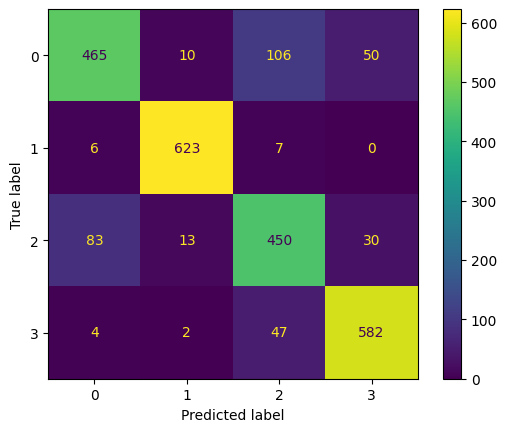

In [60]:
disp.plot()

In [61]:
print(classification_report(testY_mode, classes_x_mode))

              precision    recall  f1-score   support

         0.0       0.83      0.74      0.78       631
         1.0       0.96      0.98      0.97       636
         2.0       0.74      0.78      0.76       576
         3.0       0.88      0.92      0.90       635

    accuracy                           0.86      2478
   macro avg       0.85      0.85      0.85      2478
weighted avg       0.86      0.86      0.85      2478



In [ ]:
best_model.save(WORKDIR+"/Model/best_models_saved/lstm_classification_multiclass_class_weight_tuned")